# Data Mining Project

#### CLUSTERING: K-Means
* Choose the attributes, identify the best value of k, discuss the clusters.


### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['grid.color'] = '#333333'   # darker grid
plt.rcParams['grid.linestyle'] = '--'    # tratteggiata fine
plt.rcParams['grid.alpha'] = 0.3         # trasparente, eterea
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Griglia ultra soft per grafici dark
# plt.rcParams['grid.color'] = '#222222'   # ancora più scura e discreta


In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_clustering/k_means/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_clustering/k_means/ already exists.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
df_train.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936


In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

### Clustering K-MEANS

In [6]:
#### Scelta delle variabili per il clustering esplorativo
columns_for_clustering = [col for col in df_train.columns if col.endswith("_proc")]

"""
le colonne sono: [
 'startYear_proc',
 'awardWins_proc',
 'numVotes_proc',
 'totalImages_proc',
 'totalVideos_proc',
 'runtimeMinutes_proc',
 'totalCredits_proc',
 'criticReviewsTotal_proc',
 'awardNominationsExcludeWins_proc',
 'numRegions_proc',
 'userReviewsTotal_proc']
"""

X = df_train[columns_for_clustering]


k = 2: Inertia = 120020.79, Silhouette Score = 0.46
k = 3: Inertia = 105545.96, Silhouette Score = 0.28
k = 4: Inertia = 97365.12, Silhouette Score = 0.27
k = 5: Inertia = 88368.87, Silhouette Score = 0.22
k = 6: Inertia = 82086.91, Silhouette Score = 0.17
k = 7: Inertia = 76153.51, Silhouette Score = 0.17
k = 8: Inertia = 73049.02, Silhouette Score = 0.15
k = 9: Inertia = 69925.28, Silhouette Score = 0.15
k = 10: Inertia = 66828.56, Silhouette Score = 0.16
k = 11: Inertia = 64042.47, Silhouette Score = 0.14
k = 12: Inertia = 62152.45, Silhouette Score = 0.15
k = 13: Inertia = 60963.89, Silhouette Score = 0.13
k = 14: Inertia = 59393.63, Silhouette Score = 0.13
k = 15: Inertia = 57291.61, Silhouette Score = 0.14
k = 16: Inertia = 56100.15, Silhouette Score = 0.13
k = 17: Inertia = 54867.13, Silhouette Score = 0.13
k = 18: Inertia = 53639.36, Silhouette Score = 0.14
k = 19: Inertia = 52320.26, Silhouette Score = 0.14
k = 20: Inertia = 51199.82, Silhouette Score = 0.14
k = 21: Inertia = 

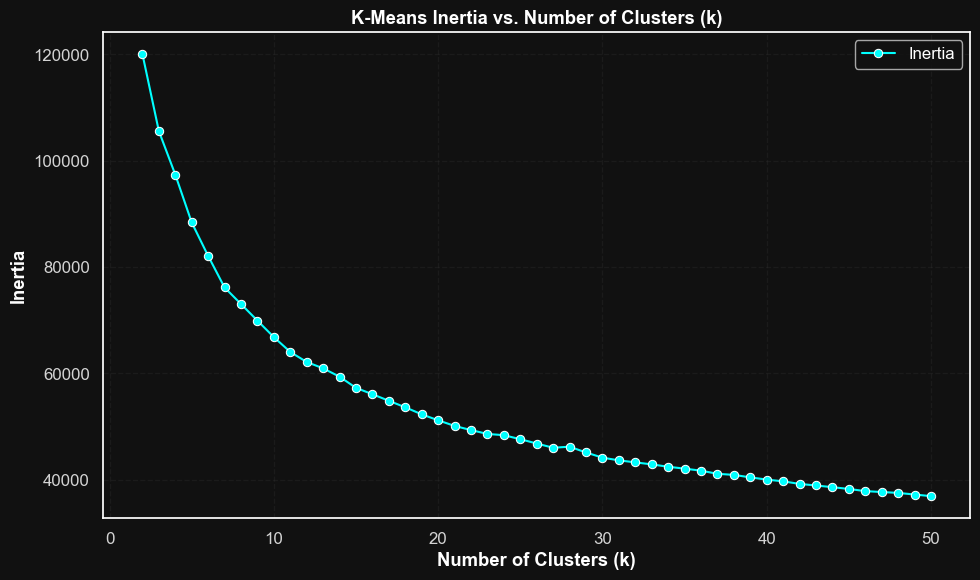

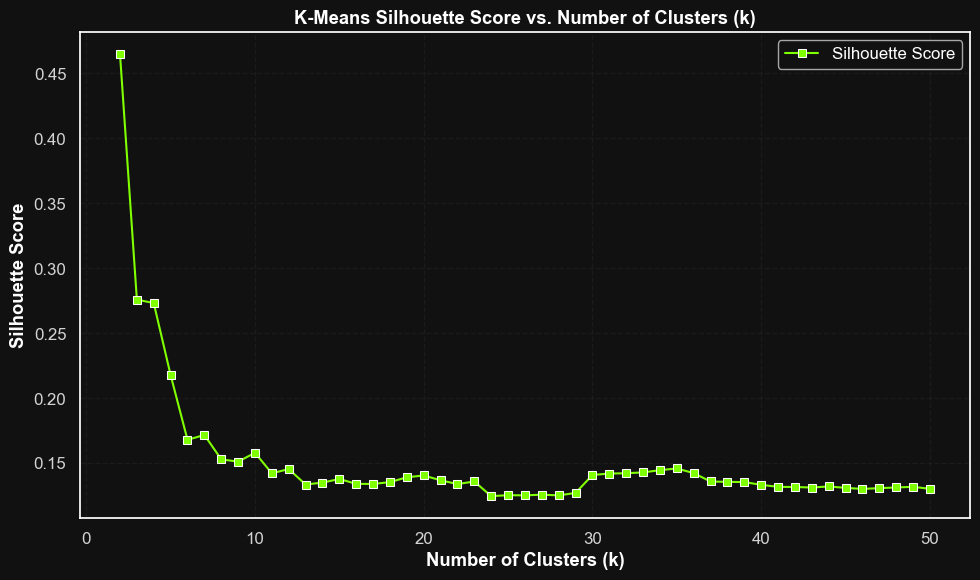

In [20]:
# Determine the optimal number of clusters (k) for K-Means using inertia and silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import matplotlib.pyplot as plt

# Lists to store evaluation metrics
inertia_values = []
silhouette_scores = []

# Range of k values to test
k_range = range(2, 51)

for k in k_range:
    kmeans = KMeans(n_clusters=k,
                    # 'k-means++' selects initial cluster centroids using sampling based on an empirical
                    # probability distribution of the points contribution to the overall inertia to speed up convergence.
                    init="k-means++",
                    n_init='auto',
                    max_iter=300, # Maximum number of iterations of the k-means algorithm for a single run.
                    algorithm="lloyd", # "lloyd" or "elkan" if clusters are naturally well defined
                    random_state=42)
    kmeans.fit(X)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X, kmeans.labels_)

    inertia_values.append(inertia)
    silhouette_scores.append(silhouette)
    print(f"k = {k}: Inertia = {inertia:.2f}, Silhouette Score = {silhouette:.2f}")
    #end_for


# --- Plot 1: Inertia Curve ---
plt.figure(figsize=(10, 6))
sns.lineplot(x=k_range, y=inertia_values, marker='o', color='#00ffff', label='Inertia')  # Ciano
plt.title("K-Means Inertia vs. Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True)
plt.tight_layout()
plt.savefig(plots_dir + "kmeans_inertia.png")
plt.show()

# --- Plot 2: Silhouette Score Curve ---
plt.figure(figsize=(10, 6))
sns.lineplot(x=k_range, y=silhouette_scores, marker='s', color='#7FFF00', label='Silhouette Score')  # Verde chiaro
plt.title("K-Means Silhouette Score vs. Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.savefig(plots_dir + "kmeans_silhouette.png")
plt.show()

#### K-MEANS CLUSTERING with optimal k

--- Performing final clustering with k = 7 ---

Clustering complete. Each data point has been assigned to a 'kmeans' cluster.
First 5 rows with their new 'kmeans' labels:
                             originalTitle  kmeans
0  Neogenic Nightmare Chapter 3: Hydro-Man       5
1                                  Looping       0
2                           Idealnaya para       0
3              MasterChef Celebrity México       5
4                               Lightdance       4

--- Analyzing Cluster Distribution ---

Counts for each cluster:
kmeans
0    6246
5    3206
2    2428
4    1483
6    1258
3     721
1     267
Name: count, dtype: int64

Percentage for each cluster:
kmeans
0    40.02 %
5    20.54 %
2    15.56 %
4      9.5 %
6     8.06 %
3     4.62 %
1     1.71 %
Name: proportion, dtype: object


/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_86962/1412646024.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')


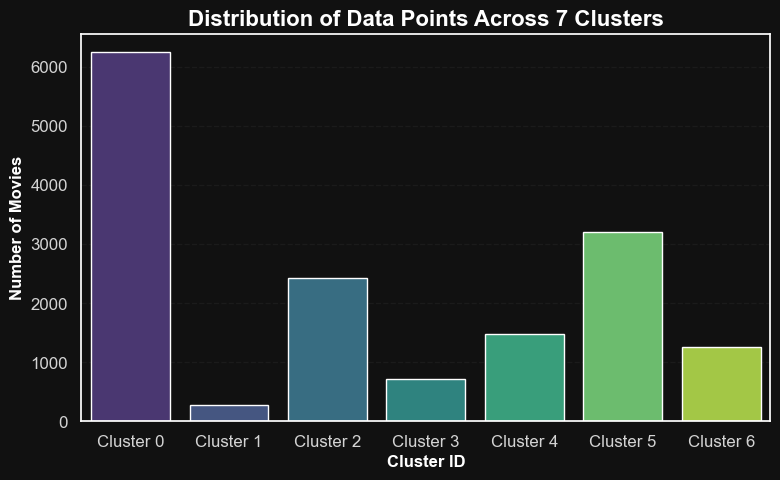

In [21]:
# --- 5.1. Final K-Means Clustering with Optimal K ---

# --- Decision Point: Choose the Optimal K ---
# Based on the Inertia (Elbow) and Silhouette Score plots from the previous step,
# we must now choose the optimal number of clusters for our analysis.
# The "elbow" in the inertia plot and the peak in the silhouette plot are our guides.
# Let's assume we've chosen a value for K.

OPTIMAL_K = 7 # The chosen number of clusters

print(f"--- Performing final clustering with k = {OPTIMAL_K} ---")

# 1. Instantiate the KMeans model with our chosen k
final_kmeans = KMeans(
                    n_clusters=OPTIMAL_K,
                    # 'k-means++' selects initial cluster centroids using sampling based on an empirical
                    # probability distribution of the points contribution to the overall inertia to speed up convergence.
                    init="k-means++",
                    n_init='auto',
                    max_iter=300, # Maximum number of iterations of the k-means algorithm for a single run.
                    algorithm="lloyd", # "lloyd" or "elkan" if clusters are naturally well defined
                    random_state=42)

# 2. Fit the model and get the cluster labels
cluster_labels = final_kmeans.fit_predict(X)

# 3. Add the cluster labels back to our dataframe with a specific name
# As per our strategy, we name this column 'kmeans'.
df_train['kmeans'] = cluster_labels

# 4. Get the coordinates of the cluster centers (centroids)
centroids = final_kmeans.cluster_centers_

print(f"\nClustering complete. Each data point has been assigned to a 'kmeans' cluster.")
print(f"First 5 rows with their new 'kmeans' labels:")
print(df_train[['originalTitle', 'kmeans']].head())

# --- 5.1.1. Analyze Cluster Distribution ---
# Before visualizing, it's crucial to understand the size of each cluster.

print("\n--- Analyzing Cluster Distribution ---")

# Calculate counts and percentages for each cluster
cluster_counts = df_train['kmeans'].value_counts()
cluster_percentages = df_train['kmeans'].value_counts(normalize=True) * 100

print("\nCounts for each cluster:")
print(cluster_counts)
print("\nPercentage for each cluster:")
print(cluster_percentages.round(2).astype(str) + ' %')

# --- Plotting the Cluster Distribution ---
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')
plt.title(f'Distribution of Data Points Across {OPTIMAL_K} Clusters', fontsize=16, weight='bold')
plt.xlabel('Cluster ID', fontsize=12, weight='bold')
plt.ylabel('Number of Movies', fontsize=12, weight='bold')
plt.xticks(ticks=cluster_counts.index, labels=[f'Cluster {i}' for i in cluster_counts.index])
plt.tight_layout()
plt.savefig(f'{plots_dir}kmeans_cluster_distribution.png', dpi=300)
plt.show()

#### Clusters 2D View with PCA

--- Generating 2D Visualization ---


/opt/anaconda3/envs/dm2_gpu/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


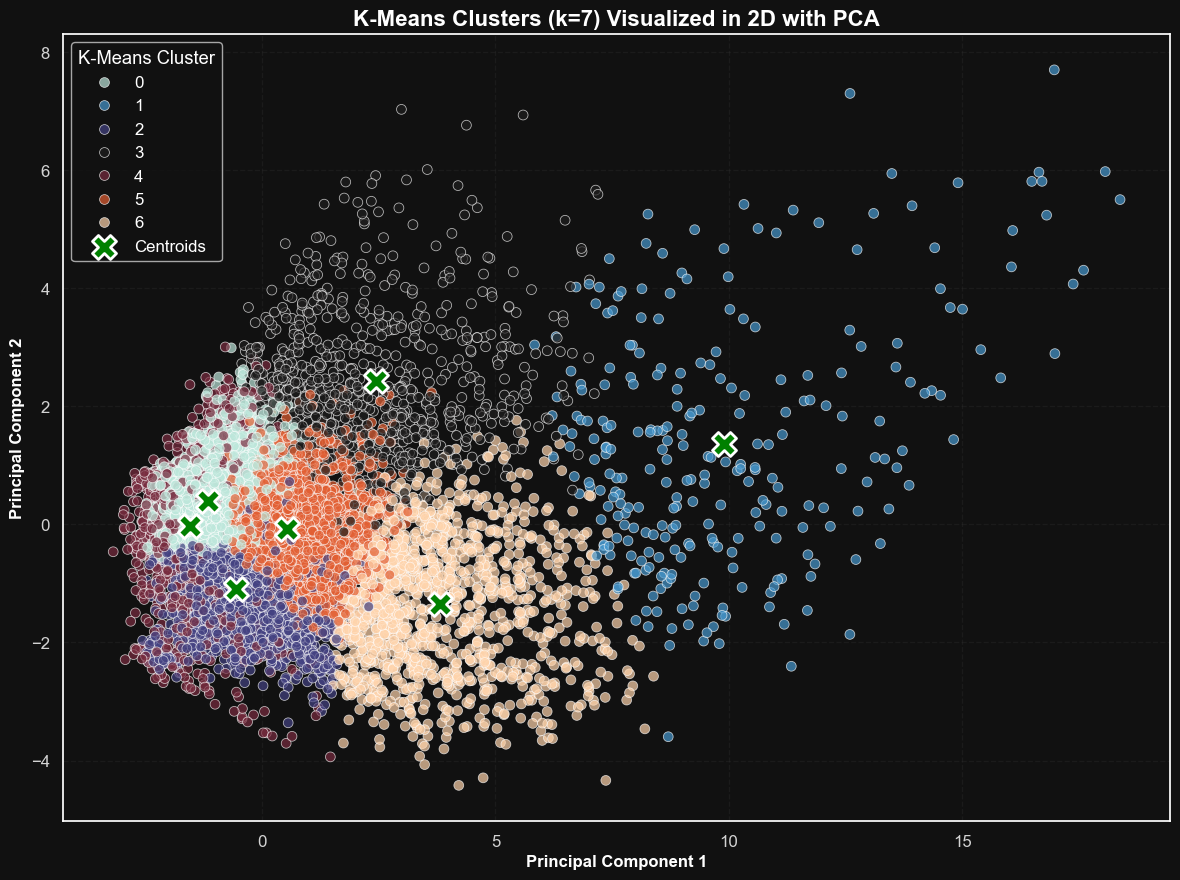


--- Generating 3D Visualization ---


/opt/anaconda3/envs/dm2_gpu/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


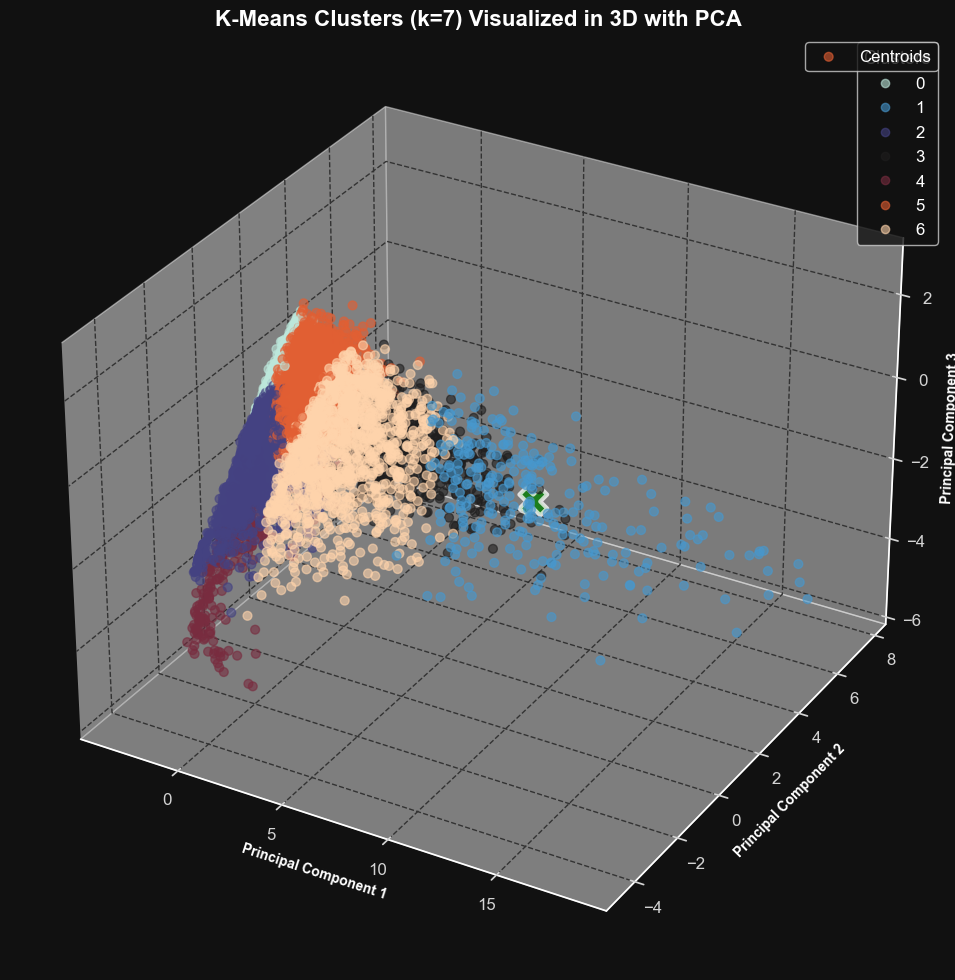

In [22]:
from sklearn.decomposition import PCA

# --- 5.2. 2D Visualization of Clusters using PCA ---
# Our data has 11 dimensions, making it impossible to visualize directly.
# We use Principal Component Analysis (PCA) to reduce the dimensionality to 2
# components, which capture the maximum possible variance of the data.
# This allows us to create a 2D "shadow" of our high-dimensional clusters.

# --- Part 1: 2D Visualization ---
print("--- Generating 2D Visualization ---")

# 1. Reduce dimensionality to 2 components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X)
centroids_pca_2d = pca_2d.transform(centroids)

# 2. Create a DataFrame for plotting, using our specific 'kmeans' column
df_pca_2d = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_pca_2d['kmeans'] = df_train['kmeans'] # Using the correct column name

# 3. Plot the 2D Clusters
plt.figure(figsize=(12, 9))
sns.scatterplot(data=df_pca_2d, x='PC1', y='PC2', hue='kmeans', palette='icefire', s=50, alpha=0.7)

# Plot the 2D centroids
plt.scatter(centroids_pca_2d[:, 0], centroids_pca_2d[:, 1],
            marker='X', s=300, linewidths=2, color='green', edgecolor='white', label='Centroids')

plt.title(f'K-Means Clusters (k={OPTIMAL_K}) Visualized in 2D with PCA', fontsize=16, weight='bold')
plt.xlabel('Principal Component 1', fontsize=12, weight='bold')
plt.ylabel('Principal Component 2', fontsize=12, weight='bold')
plt.legend(title='K-Means Cluster')
plt.grid(True)
plt.tight_layout()
plt.savefig(f'{plots_dir}kmeans_2d_pca_visualization.png', dpi=300)
plt.show()


# --- Part 2: 3D Visualization (Interactive) ---
print("\n--- Generating 3D Visualization ---")
# NOTE: For interactivity (zoom/rotate), your notebook environment may require
# a magic command like '%matplotlib widget' or '%matplotlib notebook' in a separate cell beforehand.

# 1. Reduce dimensionality to 3 components
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X)
centroids_pca_3d = pca_3d.transform(centroids)

# 2. Create the 3D plot
fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot for the 3D data points
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
                     c=df_train['kmeans'], cmap='icefire', s=40, alpha=0.6)

# Plot the 3D centroids
ax.scatter(centroids_pca_3d[:, 0], centroids_pca_3d[:, 1], centroids_pca_3d[:, 2],
           marker='X', s=400, linewidths=3, color='green', edgecolor='white', label='Centroids')

# 3. Aesthetics and Labels
ax.set_title(f'K-Means Clusters (k={OPTIMAL_K}) Visualized in 3D with PCA', fontsize=16, weight='bold')
ax.set_xlabel('Principal Component 1', fontsize=10, weight='bold')
ax.set_ylabel('Principal Component 2', fontsize=10, weight='bold')
ax.set_zlabel('Principal Component 3', fontsize=10, weight='bold')

# Create a legend
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)
ax.legend(['Centroids'], loc='upper right') # Separate legend for centroids for clarity

plt.tight_layout()
plt.savefig(f'{plots_dir}kmeans_3d_pca_visualization.png', dpi=300)
plt.show()



#### Cluster Analysis with K-Means where K = 7

In [23]:
# --- 5.3. Deep Cluster Analysis ---
# This cell performs a comprehensive analysis of the 7 clusters we've identified.
# The analysis is structured in three parts for each cluster:
# 1. Quantitative Profile: The average characteristics of the cluster on the original data scale.
# 2. Categorical Profile: The dominant title types, genres, and countries.
# 3. Exemplars: The top 3 most representative movies from each cluster.

from sklearn.preprocessing import StandardScaler
from scipy.spatial import distance

print("="*80)
print(" " * 25 + "DEEP CLUSTER ANALYSIS (K=7)")
print("="*80)

# --- SETUP FOR ANALYSIS ---

# We need to inverse-transform our processed data to make it interpretable.
# First, we identify the original numerical columns that correspond to our '_proc' features.
original_numerical_cols = [
 'startYear', 'awardWins', 'numVotes', 'totalImages', 'totalVideos',
 'runtimeMinutes', 'totalCredits', 'criticReviewsTotal',
 'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal'
]

# We re-fit a StandardScaler on the original data to be able to inverse_transform the centroids.
# This is a standard technique when the original scaler object is not available.
scaler = StandardScaler()
scaler.fit(np.log1p(df_train[original_numerical_cols]))

# Inverse transform the centroids to get their values in the original scale
centroids_original_scale = np.expm1(scaler.inverse_transform(centroids))
df_centroids = pd.DataFrame(centroids_original_scale, columns=original_numerical_cols)

# Define the categorical feature groups we want to analyze
titletype_cols = [col for col in df_train.columns if 'titleType_' in col]
genre_cols = [col for col in df_train.columns if 'genres_' in col]
country_cols = [col for col in df_train.columns if 'countryOfOrigin_' in col]


# --- ANALYSIS LOOP FOR EACH CLUSTER ---

for i in range(OPTIMAL_K):
    # Isolate the data for the current cluster
    cluster_df = df_train[df_train['kmeans'] == i]

    print(f"\n\n--- CLUSTER {i} ANALYSIS ---")
    print(f"Number of movies in this cluster: {len(cluster_df)} ({len(cluster_df)/len(df_train)*100:.2f}%)")
    print("-" * 50)

    # --- 1. Quantitative Profile (The "What") ---
    print("\n[+] Quantitative Profile (Average values on original scale):")
    print(df_centroids.loc[i].round(1))

    # --- 2. Categorical Profile (The "Who") ---
    print("\n[+] Categorical Profile (Top 3 categories in each group):")

    # TitleType Analysis
    titletype_dist = cluster_df[titletype_cols].sum().sort_values(ascending=False)
    print("\n  - Top Title Types:")
    for idx, val in titletype_dist.head(3).items():
        print(f"    - {idx.replace('titleType_', '')}: {val/len(cluster_df)*100:.1f}%")

    # Genre Analysis
    genre_dist = cluster_df[genre_cols].sum().sort_values(ascending=False)
    print("\n  - Top Genres:")
    for idx, val in genre_dist.head(3).items():
        print(f"    - {idx.replace('genres_', '')}: {val/len(cluster_df)*100:.1f}%")

    # Country Analysis
    country_dist = cluster_df[country_cols].sum().sort_values(ascending=False)
    print("\n  - Top Countries:")
    for idx, val in country_dist.head(3).items():
        print(f"    - {idx.replace('countryOfOrigin_', '')}: {val/len(cluster_df)*100:.1f}%")

    # --- 3. Exemplars (The "Face") ---
    print("\n[+] Exemplars (Top 3 most representative movies):")

    # Get the data points for the current cluster
    cluster_points = X[df_train['kmeans'] == i]
    # Get the centroid for the current cluster
    cluster_centroid = centroids[i]

    # Calculate the distance of each point in the cluster to its centroid
    distances = distance.cdist(cluster_points, cluster_centroid.reshape(1, -1))

    # Get the indices of the 3 closest points
    closest_indices = np.argsort(distances, axis=0)[:3].flatten()

    # Get the original indices from the main dataframe
    original_indices = cluster_df.iloc[closest_indices].index

    # Print the top 3 exemplars
    exemplars = df_train.loc[original_indices][['originalTitle', 'startYear', 'numVotes']]
    for index, row in exemplars.iterrows():
        print(f"    - {row['originalTitle']} ({int(row['startYear'])}) - {int(row['numVotes'])} votes")

print("\n" + "="*80)
print(" " * 30 + "ANALYSIS COMPLETE")
print("="*80)

                         DEEP CLUSTER ANALYSIS (K=7)


--- CLUSTER 0 ANALYSIS ---
Number of movies in this cluster: 6246 (40.02%)
--------------------------------------------------

[+] Quantitative Profile (Average values on original scale):
startYear                      2001.9
awardWins                         0.0
numVotes                         19.7
totalImages                       0.9
totalVideos                       0.0
runtimeMinutes                   56.2
totalCredits                     23.9
criticReviewsTotal                0.1
awardNominationsExcludeWins       0.0
numRegions                        1.4
userReviewsTotal                  0.1
Name: 0, dtype: float64

[+] Categorical Profile (Top 3 categories in each group):

  - Top Title Types:
    - tvEpisode: 35.4%
    - movie: 25.5%
    - tvSeries: 9.0%

  - Top Genres:
    - Drama: 29.0%
    - Comedy: 28.1%
    - Documentary: 15.9%

  - Top Countries:
    - US: 37.3%
    - GB: 11.4%
    - JP: 5.8%

[+] Exemplars (Top 3 m

L'Analisi dei 7 Cluster: Un Universo di Storie

* ### Cluster 1: "L'Élite di Hollywood" (1.71%)

Identikit: Questo è uno dei due cluster "immortali" che avevi previsto. È una nicchia piccolissima ma potentissima. Qui vivono i film di grande successo, mainstream e acclamati.

Le Prove: Hanno in media 19,231 voti (un'enormità!), quasi 4 premi vinti, una durata da film classico (87 min) e sono per l'80% movie. I generi sono Drama, Comedy, Action e provengono quasi esclusivamente dagli USA. Gli exemplar come "Bringing Down the House" e "Phenomenon" sono la prova del nove: film famosi, con grandi star, che tutti conoscono. Questo è il cluster del successo commerciale e di critica.

* ### Cluster 3: "Il Cinema d'Autore e da Festival" (4.62%)

Identikit: Questo è il secondo cluster di élite, ma di un tipo diverso. Non sono i blockbuster, ma i film di nicchia, spesso drammatici, che vincono premi nei festival.

Le Prove: Hanno un numero di voti molto più basso del Cluster 1 (solo 130 in media), ma hanno comunque una media di 3 premi vinti e 3 nomination. Sono per il 59% movie e per un buon 20% short. Il genere dominante è Drama (60%). È un cluster molto più internazionale (USA solo al 21%). Gli exemplar come "Filme do Desassossego" confermano la tesi: cinema impegnato, da critici, non per le masse.

* ### Cluster 4: "Il Regno dei Cortometraggi" (9.50%)

Identikit: Ecco la prova schiacciante che K=7 era la scelta giusta! Questo cluster ha isolato perfettamente il mondo dei cortometraggi e dell'animazione.

Le Prove: La durata media è di soli 8.6 minuti. Il titleType è per l'80% short. I generi dominanti sono Short (79%) e Animation (28%). Non vincono premi e hanno pochissimi voti. Senza K=7, questi film sarebbero stati mescolati con gli altri, inquinando l'analisi. Ora hanno un loro regno ben definito.

* ### Cluster 2: "Il Cinema Vintage" (15.56%)

Identikit: Questo cluster ci porta indietro nel tempo. Raggruppa le produzioni più datate, principalmente film del dopoguerra e degli anni '50.

Le Prove: L'anno medio di inizio è il 1955, il più basso di tutti i cluster. Sono principalmente movie (55%) con pochi voti e nessun premio, tipico delle produzioni di quell'epoca meno digitalizzate. Gli exemplar come "Six Gun Man" (1946) e "Torticola contre Frankensberg" (1952) sono un viaggio nella storia del cinema.

* ### Cluster 6: "I Film di Genere di Medio Successo" (8.06%)

Identikit: Questo è il cluster dei film solidi, di genere (crime, drama, comedy), che hanno avuto un buon seguito di pubblico ma non sono diventati dei blockbuster.

Le Prove: Sono per il 75% movie. Hanno un numero di voti medio rispettabile (967 voti), molte più recensioni della media e una durata da film classico (77 min). Sono il cuore del cinema "normale" che ha funzionato bene.

* ### Cluster 5: "Il Mondo delle Serie TV Americane" (20.54%)

Identikit: Questo è il regno delle produzioni televisive, principalmente americane.

Le Prove: Il titleType è un mix di tvEpisode (49%), movie (27%) e tvSeries (10%). Hanno un numero di crediti molto alto (71 in media), tipico delle produzioni seriali. Sono per il 52% americani. Gli exemplar come "William Shatner's Star Trek Memories" sono l'emblema di questo mondo.

* ### Cluster 0: "Il Grande Mare del Contenuto Generico" (40.02%)

Identikit: Infine, il cluster più grande. Questo è il "resto del mondo". Qui dentro c'è la massa indistinta di contenuti a basso impatto: episodi di serie TV poco conosciute, film a bassissimo budget, documentari minori.

Le Prove: I valori medi di tutte le metriche di successo sono praticamente zero. Pochissimi voti (20), nessun premio, poche recensioni. È il cluster con il segnale più debole, il "rumore di fondo" dell'universo IMDb.

In [19]:
#### the end.